In [1]:
import pandas as pd
import numpy as np 

In [3]:
df = pd.read_csv("breast_cancer.csv")
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [5]:
df.isnull().sum()

id                         0
diagnosis                  0
radius_mean                0
texture_mean               0
perimeter_mean             0
area_mean                  0
smoothness_mean            0
compactness_mean           0
concavity_mean             0
concave points_mean        0
symmetry_mean              0
fractal_dimension_mean     0
radius_se                  0
texture_se                 0
perimeter_se               0
area_se                    0
smoothness_se              0
compactness_se             0
concavity_se               0
concave points_se          0
symmetry_se                0
fractal_dimension_se       0
radius_worst               0
texture_worst              0
perimeter_worst            0
area_worst                 0
smoothness_worst           0
compactness_worst          0
concavity_worst            0
concave points_worst       0
symmetry_worst             0
fractal_dimension_worst    0
dtype: int64

In [6]:
from sklearn.preprocessing import LabelEncoder

In [9]:
label_encoders = LabelEncoder()
df["diagnosis"] = label_encoders.fit_transform(df['diagnosis'])

In [10]:
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [12]:
x= df.drop(["id", "diagnosis"], axis = 1)
y = df["diagnosis"]

In [13]:
from sklearn.model_selection import train_test_split

In [14]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 42)

In [16]:
x_train.shape, y_train.shape

((455, 30), (455,))

In [17]:
from sklearn.preprocessing import StandardScaler

In [18]:
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [20]:
from sklearn.linear_model import LogisticRegression

In [21]:
model = LogisticRegression()
model.fit(x_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [22]:
y_test_pred = model.predict(x_test)  

In [23]:
y_test_pred_proba = model.predict_proba (x_test)[:, 1]

In [24]:
from sklearn.metrics import accuracy_score, confusion_matrix, roc_auc_score, roc_curve

In [26]:
test_accuracy = accuracy_score (y_test, y_test_pred)
test_accuracy

0.9736842105263158

In [27]:
cm = confusion_matrix(y_test, y_test_pred)
cm

array([[70,  1],
       [ 2, 41]])

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

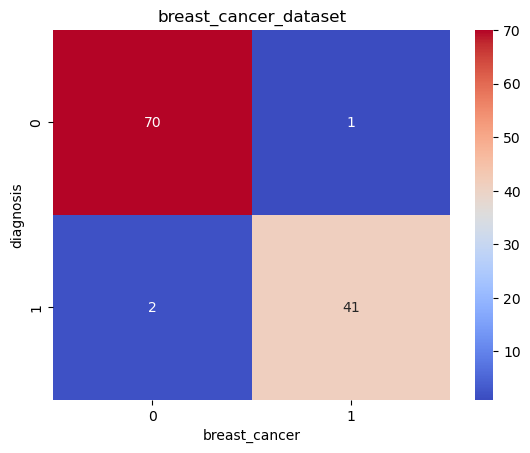

In [32]:
sns.heatmap(cm, annot = True, fmt = "d", cmap = "coolwarm")
plt.xlabel("breast_cancer")
plt.ylabel("diagnosis")
plt.title("breast_cancer_dataset")
plt.show()

In [33]:
roc_auc = roc_auc_score(y_test, y_test_pred_proba)
roc_auc

0.99737962659679

In [34]:
fpr,tpr, threshold = roc_curve(y_test, y_test_pred_proba)

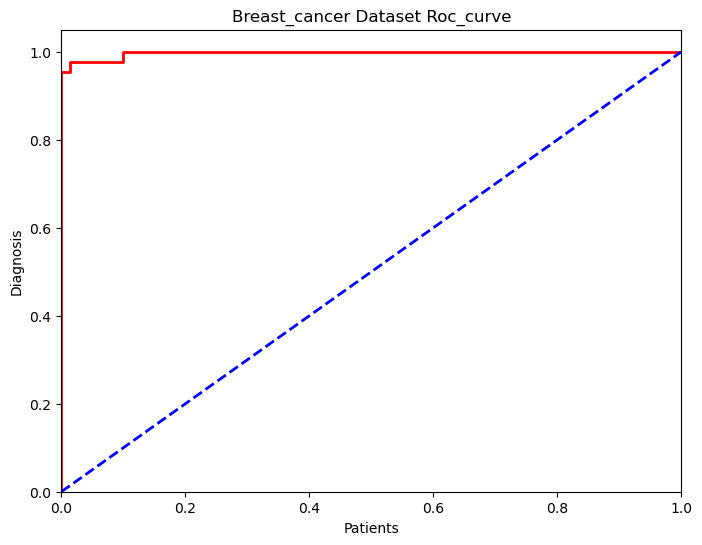

In [37]:
plt.figure(figsize= (8,6))
plt.plot(fpr, tpr, color = "red", lw = 2, label = (f" roc_curve{roc_auc}"))
plt.plot([0, 1], [0,1], color = "blue", lw = 2, linestyle = "--", label = "RandomGuessing")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("Patients")
plt.ylabel("Diagnosis")
plt.title("Breast_cancer Dataset Roc_curve")
plt.show()

In [38]:
y_train_pred = model.predict(x_train)

In [39]:
y_train_pred_proba = model.predict_proba(x_train)[: 1]

In [40]:
train_accuracy = accuracy_score(y_train, y_train_pred)

In [41]:
train_accuracy

0.9868131868131869

In [42]:
print(test_accuracy)
print(train_accuracy)

0.9736842105263158
0.9868131868131869


In [43]:
sns.pairplot(df, hue = "diagnosis")